# Data Collection Notebook

In [1]:

import tensorflow as tf
import os

print("TensorFlow Version:", tf.__version__)
print("Current Device:", "CPU")
print("Working Directory:", os.getcwd())



TensorFlow Version: 2.21.0
Current Device: CPU
Working Directory: /content


In [2]:

from google.colab import files
import os

uploaded = files.upload()

os.makedirs("/root/.kaggle", exist_ok=True)

if "kaggle.json" in uploaded:
    with open("/root/.kaggle/kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])

    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    print("Kaggle authentication file configured!")
else:
    print("Please upload kaggle.json")


Saving kaggle.json to kaggle (1).json
Please upload kaggle.json


In [4]:

import os
import json
from pathlib import Path

# Kaggle credentials location
kaggle_path = Path("/root/.kaggle/kaggle.json")

print("File exists:", kaggle_path.exists())

if kaggle_path.exists():
    with open(kaggle_path, "r") as f:
        credentials = json.load(f)

    print("Credential keys:", list(credentials.keys()))

    # Support both legacy and token authentication
    if "username" in credentials and "key" in credentials:
        os.environ["KAGGLE_USERNAME"] = credentials["username"]
        os.environ["KAGGLE_KEY"] = credentials["key"]
        print("Legacy Kaggle credentials configured.")
    elif "token" in credentials:
        os.environ["KAGGLE_API_TOKEN"] = credentials["token"]
        print("Kaggle API token configured.")
    else:
        print("Unrecognized credential format.")
else:
    print("kaggle.json not found. Please upload again.")


File exists: True
Credential keys: ['username', 'key']
Legacy Kaggle credentials configured.


In [5]:

from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

print("Kaggle authentication successful!")

competition = "aptos2019-blindness-detection"

try:
    dataset_files = api.competition_list_files(competition)

    print("\nAPTOS 2019 files:")
    for file in dataset_files:
        print(file.name)

except Exception as e:
    print("Dataset access error:", str(e))



Kaggle authentication successful!

APTOS 2019 files:
Dataset access error: 'ApiListDataFilesResponse' object is not iterable


In [6]:

competition = "aptos2019-blindness-detection"

try:
    response = api.competition_list_files(competition)

    print("APTOS 2019 Dataset Files:\n")

    for file in response.files:
        print("File:", file.name)

except Exception as e:
    print("Error:", str(e))


APTOS 2019 Dataset Files:

File: sample_submission.csv
File: test.csv
File: test_images/0005cfc8afb6.png
File: test_images/003f0afdcd15.png
File: test_images/006efc72b638.png
File: test_images/00836aaacf06.png
File: test_images/009245722fa4.png
File: test_images/009c019a7309.png
File: test_images/010d915e229a.png
File: test_images/0111b949947e.png
File: test_images/01499815e469.png
File: test_images/0167076e7089.png
File: test_images/01c31b10ab99.png
File: test_images/01c5ba195207.png
File: test_images/01e4d86b3a30.png
File: test_images/020921b796d5.png
File: test_images/020f6983114d.png
File: test_images/021c207614d6.png
File: test_images/0229c0a80d42.png
File: test_images/024d0a225db1.png


In [7]:

import os

os.makedirs("/content/aptos_data", exist_ok=True)

try:
    api.competition_download_file(
        competition="aptos2019-blindness-detection",
        file_name="train_images/000c1434d8d7.png",
        path="/content/aptos_data",
        quiet=False
    )

    print("\nDownload request completed!")
    print("Downloaded files:",
          os.listdir("/content/aptos_data"))

except Exception as e:
    print("Download error:", str(e))


000c1434d8d7.png.zip: Skipping, found more recently modified local copy (use --force to force download)

Download request completed!
Downloaded files: ['train.csv', 'train_500.csv', '000c1434d8d7.png.zip', 'train_images', 'test_100.csv']


In [8]:

import os
import zipfile
import pandas as pd

folder = "/content/aptos_data"

api.competition_download_file(
    competition="aptos2019-blindness-detection",
    file_name="train.csv",
    path=folder,
    quiet=False
)

# Extract CSV if Kaggle returns a ZIP
zip_path = os.path.join(folder, "train.csv.zip")

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(folder)

# Read labels
df = pd.read_csv(os.path.join(folder, "train.csv"))

print("\nTotal labelled images:", len(df))
print("\nClass distribution:")
print(df["diagnosis"].value_counts().sort_index())

print("\nFirst 5 rows:")
print(df.head())


train.csv: Skipping, found more recently modified local copy (use --force to force download)

Total labelled images: 3662

Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

First 5 rows:
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0


In [9]:

import pandas as pd

train_parts = []
test_parts = []

for label in range(5):

    class_data = df[df["diagnosis"] == label]

    selected = class_data.sample(
        n=120,
        random_state=42
    )

    train_parts.append(selected.iloc[:100])
    test_parts.append(selected.iloc[100:120])

train_df = pd.concat(
    train_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

import pandas as pd

train_parts = []
test_parts = []

for label in range(5):

    class_data = df[df["diagnosis"] == label]

    selected = class_data.sample(
        n=120,
        random_state=42
    )

    train_parts.append(selected.iloc[:100])
    test_parts.append(selected.iloc[100:120])

train_df = pd.concat(
    train_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

test_df = pd.concat(
    test_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Save selected filenames and labels
train_df.to_csv(
    "/content/aptos_data/train_500.csv",
    index=False
)

test_df.to_csv(
    "/content/aptos_data/test_100.csv",
    index=False
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["diagnosis"].value_counts().sort_index())

print("\nOverlap:",
      len(set(train_df["id_code"]) &
          set(test_df["id_code"])))

test_df = pd.concat(
    test_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Save selected filenames and labels
train_df.to_csv(
    "/content/aptos_data/train_500.csv",
    index=False
)

test_df.to_csv(
    "/content/aptos_data/test_100.csv",
    index=False
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["diagnosis"].value_counts().sort_index())

print("\nOverlap:",
      len(set(train_df["id_code"]) &
          set(test_df["id_code"])))


Training images: 500
Testing images: 100

Training class distribution:
diagnosis
0    100
1    100
2    100
3    100
4    100
Name: count, dtype: int64

Testing class distribution:
diagnosis
0    20
1    20
2    20
3    20
4    20
Name: count, dtype: int64

Overlap: 0
Training images: 500
Testing images: 100

Training class distribution:
diagnosis
0    100
1    100
2    100
3    100
4    100
Name: count, dtype: int64

Testing class distribution:
diagnosis
0    20
1    20
2    20
3    20
4    20
Name: count, dtype: int64

Overlap: 0


In [10]:

import pandas as pd

train_parts = []
test_parts = []

for label in range(5):

    class_data = df[df["diagnosis"] == label]

    selected = class_data.sample(
        n=120,
        random_state=42
    )

    train_parts.append(selected.iloc[:100])
    test_parts.append(selected.iloc[100:120])

train_df = pd.concat(
    train_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

test_df = pd.concat(
    test_parts, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Save selected filenames and labels
train_df.to_csv(
    "/content/aptos_data/train_500.csv",
    index=False
)

test_df.to_csv(
    "/content/aptos_data/test_100.csv",
    index=False
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df["diagnosis"].value_counts().sort_index())

print("\nOverlap:",
      len(set(train_df["id_code"]) &
          set(test_df["id_code"])))


Training images: 500
Testing images: 100

Training class distribution:
diagnosis
0    100
1    100
2    100
3    100
4    100
Name: count, dtype: int64

Testing class distribution:
diagnosis
0    20
1    20
2    20
3    20
4    20
Name: count, dtype: int64

Overlap: 0


In [11]:

import os
import zipfile
from tqdm.auto import tqdm

train_folder = "/content/aptos_data/train_images"
os.makedirs(train_folder, exist_ok=True)

success = 0
failed = []

for img_id in tqdm(train_df["id_code"], desc="Training images"):

    image_path = os.path.join(
        train_folder, f"{img_id}.png"
    )

    if os.path.exists(image_path):
        success += 1
        continue

    try:
        api.competition_download_file(
            competition="aptos2019-blindness-detection",
            file_name=f"train_images/{img_id}.png",
            path=train_folder,
            quiet=True
        )

        zip_path = os.path.join(
            train_folder, f"{img_id}.png.zip"
        )

        if os.path.exists(zip_path):
            with zipfile.ZipFile(zip_path, "r") as z:
                for member in z.namelist():
                    if member.endswith(".png"):
                        with z.open(member) as src:
                            with open(image_path, "wb") as dst:
                                import shutil
                                shutil.copyfileobj(src, dst)
                        break

            os.remove(zip_path)

        if os.path.exists(image_path):
            success += 1
        else:
            failed.append(img_id)

    except Exception as e:
        failed.append(img_id)
        print(f"\nFailed: {img_id} - {e}")

print("\nTraining images downloaded:", success)
print("Failed images:", len(failed))


Training images:   0%|          | 0/500 [00:00<?, ?it/s]


Training images downloaded: 500
Failed images: 0


In [12]:

import os
import zipfile
import shutil
from tqdm.auto import tqdm

test_folder = "/content/aptos_data/test_images"
os.makedirs(test_folder, exist_ok=True)

success = 0
failed = []

for img_id in tqdm(test_df["id_code"], desc="Testing images"):

    image_path = os.path.join(
        test_folder, f"{img_id}.png"
    )

    if os.path.exists(image_path):
        success += 1
        continue

    try:
        api.competition_download_file(
            competition="aptos2019-blindness-detection",
            file_name=f"train_images/{img_id}.png",
            path=test_folder,
            quiet=True
        )

        zip_path = os.path.join(
            test_folder, f"{img_id}.png.zip"
        )

        if os.path.exists(zip_path):
            with zipfile.ZipFile(zip_path, "r") as z:
                for member in z.namelist():
                    if member.endswith(".png"):
                        with z.open(member) as src:
                            with open(image_path, "wb") as dst:
                                shutil.copyfileobj(src, dst)
                        break

            os.remove(zip_path)

        if os.path.exists(image_path):
            success += 1
        else:
            failed.append(img_id)

    except Exception as e:
        failed.append(img_id)
        print(f"\nFailed: {img_id} - {e}")

print("\nTesting images downloaded:", success)
print("Failed images:", len(failed))
print("Total images:", 500 + success)


Testing images:   0%|          | 0/100 [00:00<?, ?it/s]


Testing images downloaded: 100
Failed images: 0
Total images: 600


Training images: 500
Testing images: 100


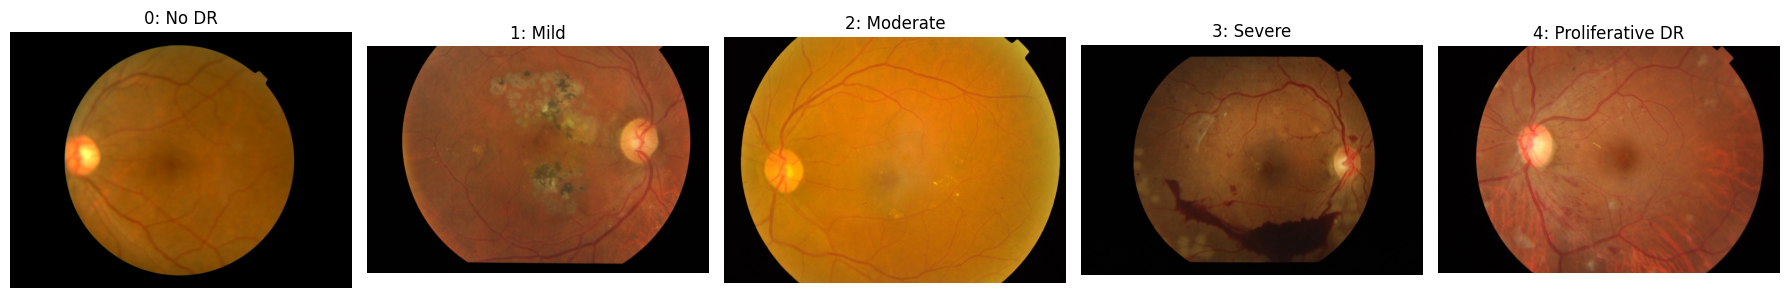

Dataset verification completed!


In [13]:

import os
from PIL import Image
import matplotlib.pyplot as plt

train_folder = "/content/aptos_data/train_images"
test_folder = "/content/aptos_data/test_images"

train_count = len([
    f for f in os.listdir(train_folder)
    if f.endswith(".png")
])

test_count = len([
    f for f in os.listdir(test_folder)
    if f.endswith(".png")
])

print("Training images:", train_count)
print("Testing images:", test_count)

class_names = [
    "No DR", "Mild", "Moderate",
    "Severe", "Proliferative DR"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for label in range(5):
    sample = train_df[
        train_df["diagnosis"] == label
    ].iloc[0]

    image_path = os.path.join(
        train_folder, sample["id_code"] + ".png"
    )

    img = Image.open(image_path).convert("RGB")

    axes[label].imshow(img)
    axes[label].set_title(
        f"{label}: {class_names[label]}"
    )
    axes[label].axis("off")

plt.tight_layout()
plt.show()

print("Dataset verification completed!")


In [15]:

import os
from PIL import Image
from tqdm.auto import tqdm

BASE = "/content/aptos_data"

def preprocess_images(input_folder, output_folder):
    os.makedirs(output_folder, exist_ok=True)

    processed = 0
    failed = []

    for filename in tqdm(os.listdir(input_folder)):
        if not filename.lower().endswith(".png"):
            continue

        try:
            input_path = os.path.join(input_folder, filename)
            output_path = os.path.join(
                output_folder,
                filename.replace(".png", ".jpg")
            )

            with Image.open(input_path) as img:
                img = img.convert("RGB")
                img = img.resize((224, 224))
                img.save(output_path, quality=90)

            processed += 1

        except Exception as e:
            failed.append((filename, str(e)))

    return processed, failed

train_count, train_failed = preprocess_images(
    BASE + "/train_images",
    BASE + "/processed_train"
)

test_count, test_failed = preprocess_images(
    BASE + "/test_images",
    BASE + "/processed_test"
)

print("\nTraining processed:", train_count)
print("Testing processed:", test_count)
print("Failed:", len(train_failed) + len(test_failed))


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


Training processed: 500
Testing processed: 100
Failed: 0


In [16]:

import tensorflow as tf
import pandas as pd
import os
from sklearn.model_selection import train_test_split

BASE = "/content/aptos_data"

# Split 500 images into train and validation
train_split, val_split = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["diagnosis"],
    random_state=42
)

def create_dataset(dataframe, folder, shuffle=False):

    image_paths = [
        os.path.join(
            BASE, folder, img_id + ".jpg"
        )
        for img_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, (224, 224))
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(400)

    return ds.batch(16).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(
    train_split, "processed_train", shuffle=True
)

val_ds = create_dataset(
    val_split, "processed_train"
)

test_ds = create_dataset(
    test_df, "processed_test"
)

print("Training:", len(train_split))
print("Validation:", len(val_split))
print("Testing:", len(test_df))

print("\nTensorFlow datasets ready!")


Training: 400
Validation: 100
Testing: 100

TensorFlow datasets ready!


In [17]:

import tensorflow as tf

# Read one batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Sample labels:", labels.numpy())

print("\nDataset verification successful!")


Image batch shape: (16, 224, 224, 3)
Labels shape: (16,)
Image dtype: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0
Sample labels: [3 4 2 0 0 3 3 1 4 1 0 4 2 1 2 4]

Dataset verification successful!


In [18]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

# Pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Model architecture
inputs = layers.Input(shape=(224, 224, 3))

# EfficientNetB0 already handles input rescaling
x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)

# 5 DR severity classes
outputs = layers.Dense(
    5, activation="softmax"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs
)

print("EfficientNetB0 model created successfully!")
print("Base model frozen:", not base_model.trainable)

model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 model created successfully!
Base model frozen: True


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [19]:

import tensorflow as tf

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("Model compiled successfully!")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")
print("GPU training not started yet.")


Model compiled successfully!
Optimizer: Adam
Learning rate: 0.001
Loss: Sparse Categorical Crossentropy
Metric: Accuracy
GPU training not started yet.


In [20]:

import tensorflow as tf
import os

# Folder to save trained models
os.makedirs("/content/saved_models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="/content/saved_models/best_efficientnet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Training callbacks configured successfully!")
print("EarlyStopping: Enabled")
print("ModelCheckpoint: Enabled")
print("ReduceLROnPlateau: Enabled")
print("GPU training not started.")


Training callbacks configured successfully!
EarlyStopping: Enabled
ModelCheckpoint: Enabled
ReduceLROnPlateau: Enabled
GPU training not started.
